In [1]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt 
from sklearn.tree import DecisionTreeRegressor 
from sklearn.tree import plot_tree
from sklearn.model_selection import train_test_split ,cross_val_score
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler, OrdinalEncoder

In [2]:
%store -r combined_df
combined_df


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
644,MS,F,19,R,GT3,T,2,3,services,other,...,5,4,2,1,2,5,4,10,11,10
645,MS,F,18,U,LE3,T,3,1,teacher,services,...,4,3,4,1,1,1,4,15,15,16
646,MS,F,18,U,GT3,T,1,1,other,other,...,1,1,1,1,1,5,6,11,12,9
647,MS,M,17,U,LE3,T,3,1,services,services,...,2,4,5,3,4,2,6,10,10,10


In [3]:
df = combined_df.reset_index(drop=True)

df = df.drop(columns=['sex','address','famsize','Pstatus','Fedu','Mjob','Fjob','guardian','schoolsup','famsup','paid','activities','romantic','goout'])

df

,school,age,Medu,reason,traveltime,studytime,failures,nursery,higher,internet,famrel,freetime,Dalc,Walc,health,absences,G1,G2,G3
0,GP,18,4,course,2,2,0,yes,yes,no,4,3,1,1,3,4,0,11,11
1,GP,17,1,course,1,2,0,no,yes,yes,5,3,1,1,3,2,9,11,11
2,GP,15,1,other,1,2,0,yes,yes,yes,4,3,2,3,3,6,12,13,12
3,GP,15,4,home,1,3,0,yes,yes,yes,3,2,1,1,5,0,14,14,14
4,GP,16,3,home,1,2,0,yes,yes,no,4,3,1,2,5,0,11,13,13
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
644,MS,19,2,course,1,3,1,no,yes,yes,5,4,1,2,5,4,10,11,10
645,MS,18,3,course,1,2,0,yes,yes,yes,4,3,1,1,1,4,15,15,16
646,MS,18,1,course,2,2,0,yes,yes,no,1,1,1,1,5,6,11,12,9
647,MS,17,3,course,2,1,0,no,yes,yes,2,4,3,4,2,6,10,10,10


In [4]:
X = df.drop(columns=["G3", "G2", "G1"])
y = df["G3"]


It is time to chose what is the best Model to fit the data, for better prediction accuracy.

In [5]:
X.dtypes

school        object
age            int64
Medu           int64
reason        object
traveltime     int64
studytime      int64
failures       int64
nursery       object
higher        object
internet      object
famrel         int64
freetime       int64
Dalc           int64
Walc           int64
health         int64
absences       int64
dtype: object

In [6]:
X_encoded = pd.get_dummies(X, columns=['school', 'reason', 'nursery', 'higher', 'internet'])
X_encoded.head()

,age,Medu,traveltime,studytime,failures,famrel,freetime,Dalc,Walc,health,...,reason_course,reason_home,reason_other,reason_reputation,nursery_no,nursery_yes,higher_no,higher_yes,internet_no,internet_yes
0,18,4,2,2,0,4,3,1,1,3,...,True,False,False,False,False,True,False,True,True,False
1,17,1,1,2,0,5,3,1,1,3,...,True,False,False,False,True,False,False,True,False,True
2,15,1,1,2,0,4,3,2,3,3,...,False,False,True,False,False,True,False,True,False,True
3,15,4,1,3,0,3,2,1,1,5,...,False,True,False,False,False,True,False,True,False,True
4,16,3,1,2,0,4,3,1,2,5,...,False,True,False,False,False,True,False,True,True,False


In [7]:
X_train, X_test, y_train, y_test = train_test_split(X_encoded,y,random_state = 0)

dt = DecisionTreeRegressor(random_state = 0)
dt = dt.fit(X_train, y_train)

In [8]:
train_preds = dt.predict(X_train)
test_preds = dt.predict(X_test)

train_rmse = np.sqrt(mean_squared_error(y_train, train_preds))
test_rmse = np.sqrt(mean_squared_error(y_test, test_preds))

print('Train RMSE:', train_rmse)
print('Test RMSE:', test_rmse)

Train RMSE: 0.0
Test RMSE: 4.411362907241537


Now we see that the Decision Tree fits the training data like a glove, shown in the difference of 4.41 points

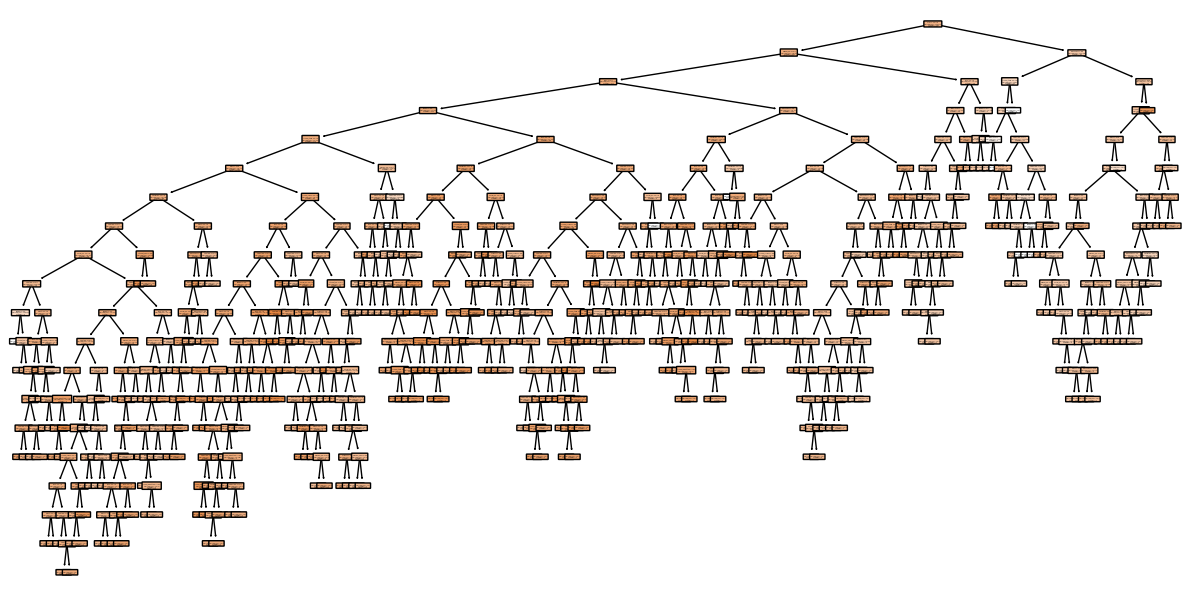

In [9]:
plt.figure(figsize=(15,7.5))
plot_tree(dt,
         filled = True,
         rounded = True,
         feature_names = X_encoded.columns)
plt.show()

In [10]:
path = dt.cost_complexity_pruning_path(X_train, y_train)
ccp_alphas = path.ccp_alphas
ccp_alphas = ccp_alphas[:-1]  

dts = []  


for alpha in ccp_alphas:
    dt = DecisionTreeRegressor(random_state=0, ccp_alpha=alpha)
    dt.fit(X_train, y_train)
    dts.append(dt)


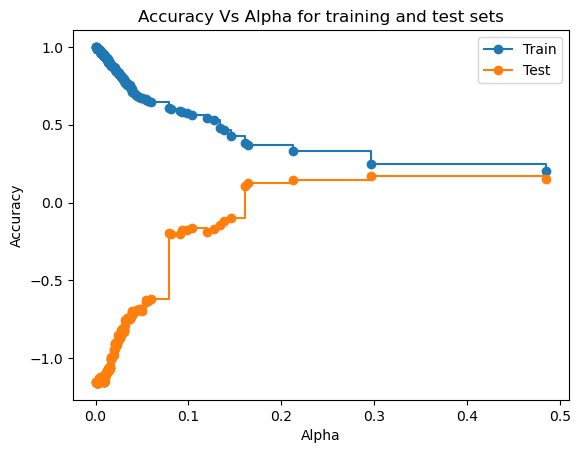

In [11]:
train_scores = [dt.score(X_train, y_train) for dt in dts]
test_scores = [dt.score(X_test, y_test) for dt in dts]

fig, ax= plt.subplots()
ax.set_xlabel("Alpha")
ax.set_ylabel("Accuracy")
ax.set_title("Accuracy Vs Alpha for training and test sets")
ax.plot(ccp_alphas, train_scores, marker = 'o',label = 'Train', drawstyle = 'steps-post')
ax.plot(ccp_alphas, test_scores, marker = 'o', label = 'Test', drawstyle = 'steps-post')
ax.legend()
plt.show()

The Decision tree as shown in the figure above, overfits the Training data, while it uderfits the testing data at the very start, but then they make it in a sweetspot where alpha is about 0.3

Using different testing and training data sets with the same alpha results in different accuracies , thats why it is fendamental to use cross validation 

<Axes: xlabel='alpha'>

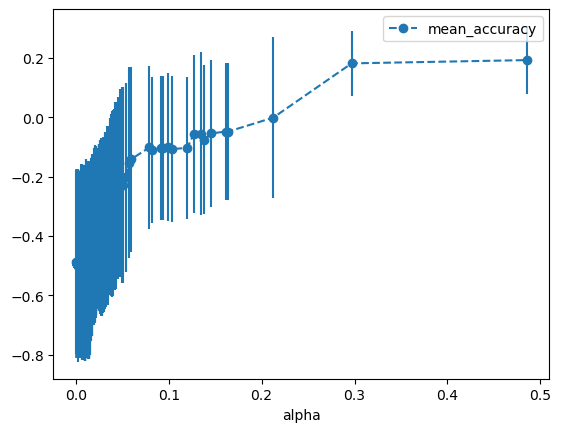

In [12]:
alpha_loop_values = []

for ccp_alpha in ccp_alphas:
    dt = DecisionTreeRegressor(random_state = 0, ccp_alpha = ccp_alpha)
    scores = cross_val_score(dt, X_train, y_train, cv= 5)
    alpha_loop_values.append([ccp_alpha, np.mean(scores),np.std(scores)])


alpha_results= pd.DataFrame(alpha_loop_values, columns= ['alpha','mean_accuracy','std'])

alpha_results.plot(x= 'alpha',
                  y = 'mean_accuracy',
                  yerr = 'std',
                  marker= 'o',
                  linestyle = '--')

In [13]:
optimal_alpha= alpha_results[(alpha_results['alpha']> 0.29) 
    & 
    (alpha_results['alpha']< 0.33)] ['alpha']
optimal_alpha

282    0.296911
Name: alpha, dtype: float64

In [14]:
optimal_alpha = float(optimal_alpha)
optimal_alpha

C:\Users\Fatima zahra\AppData\Local\Temp\ipykernel_4140\2260763681.py:1: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  optimal_alpha = float(optimal_alpha)


0.2969109437169035

In [15]:
dt_pruned = DecisionTreeRegressor(random_state = 0, ccp_alpha= optimal_alpha)
dt_pruned = dt_pruned.fit(X_train, y_train)


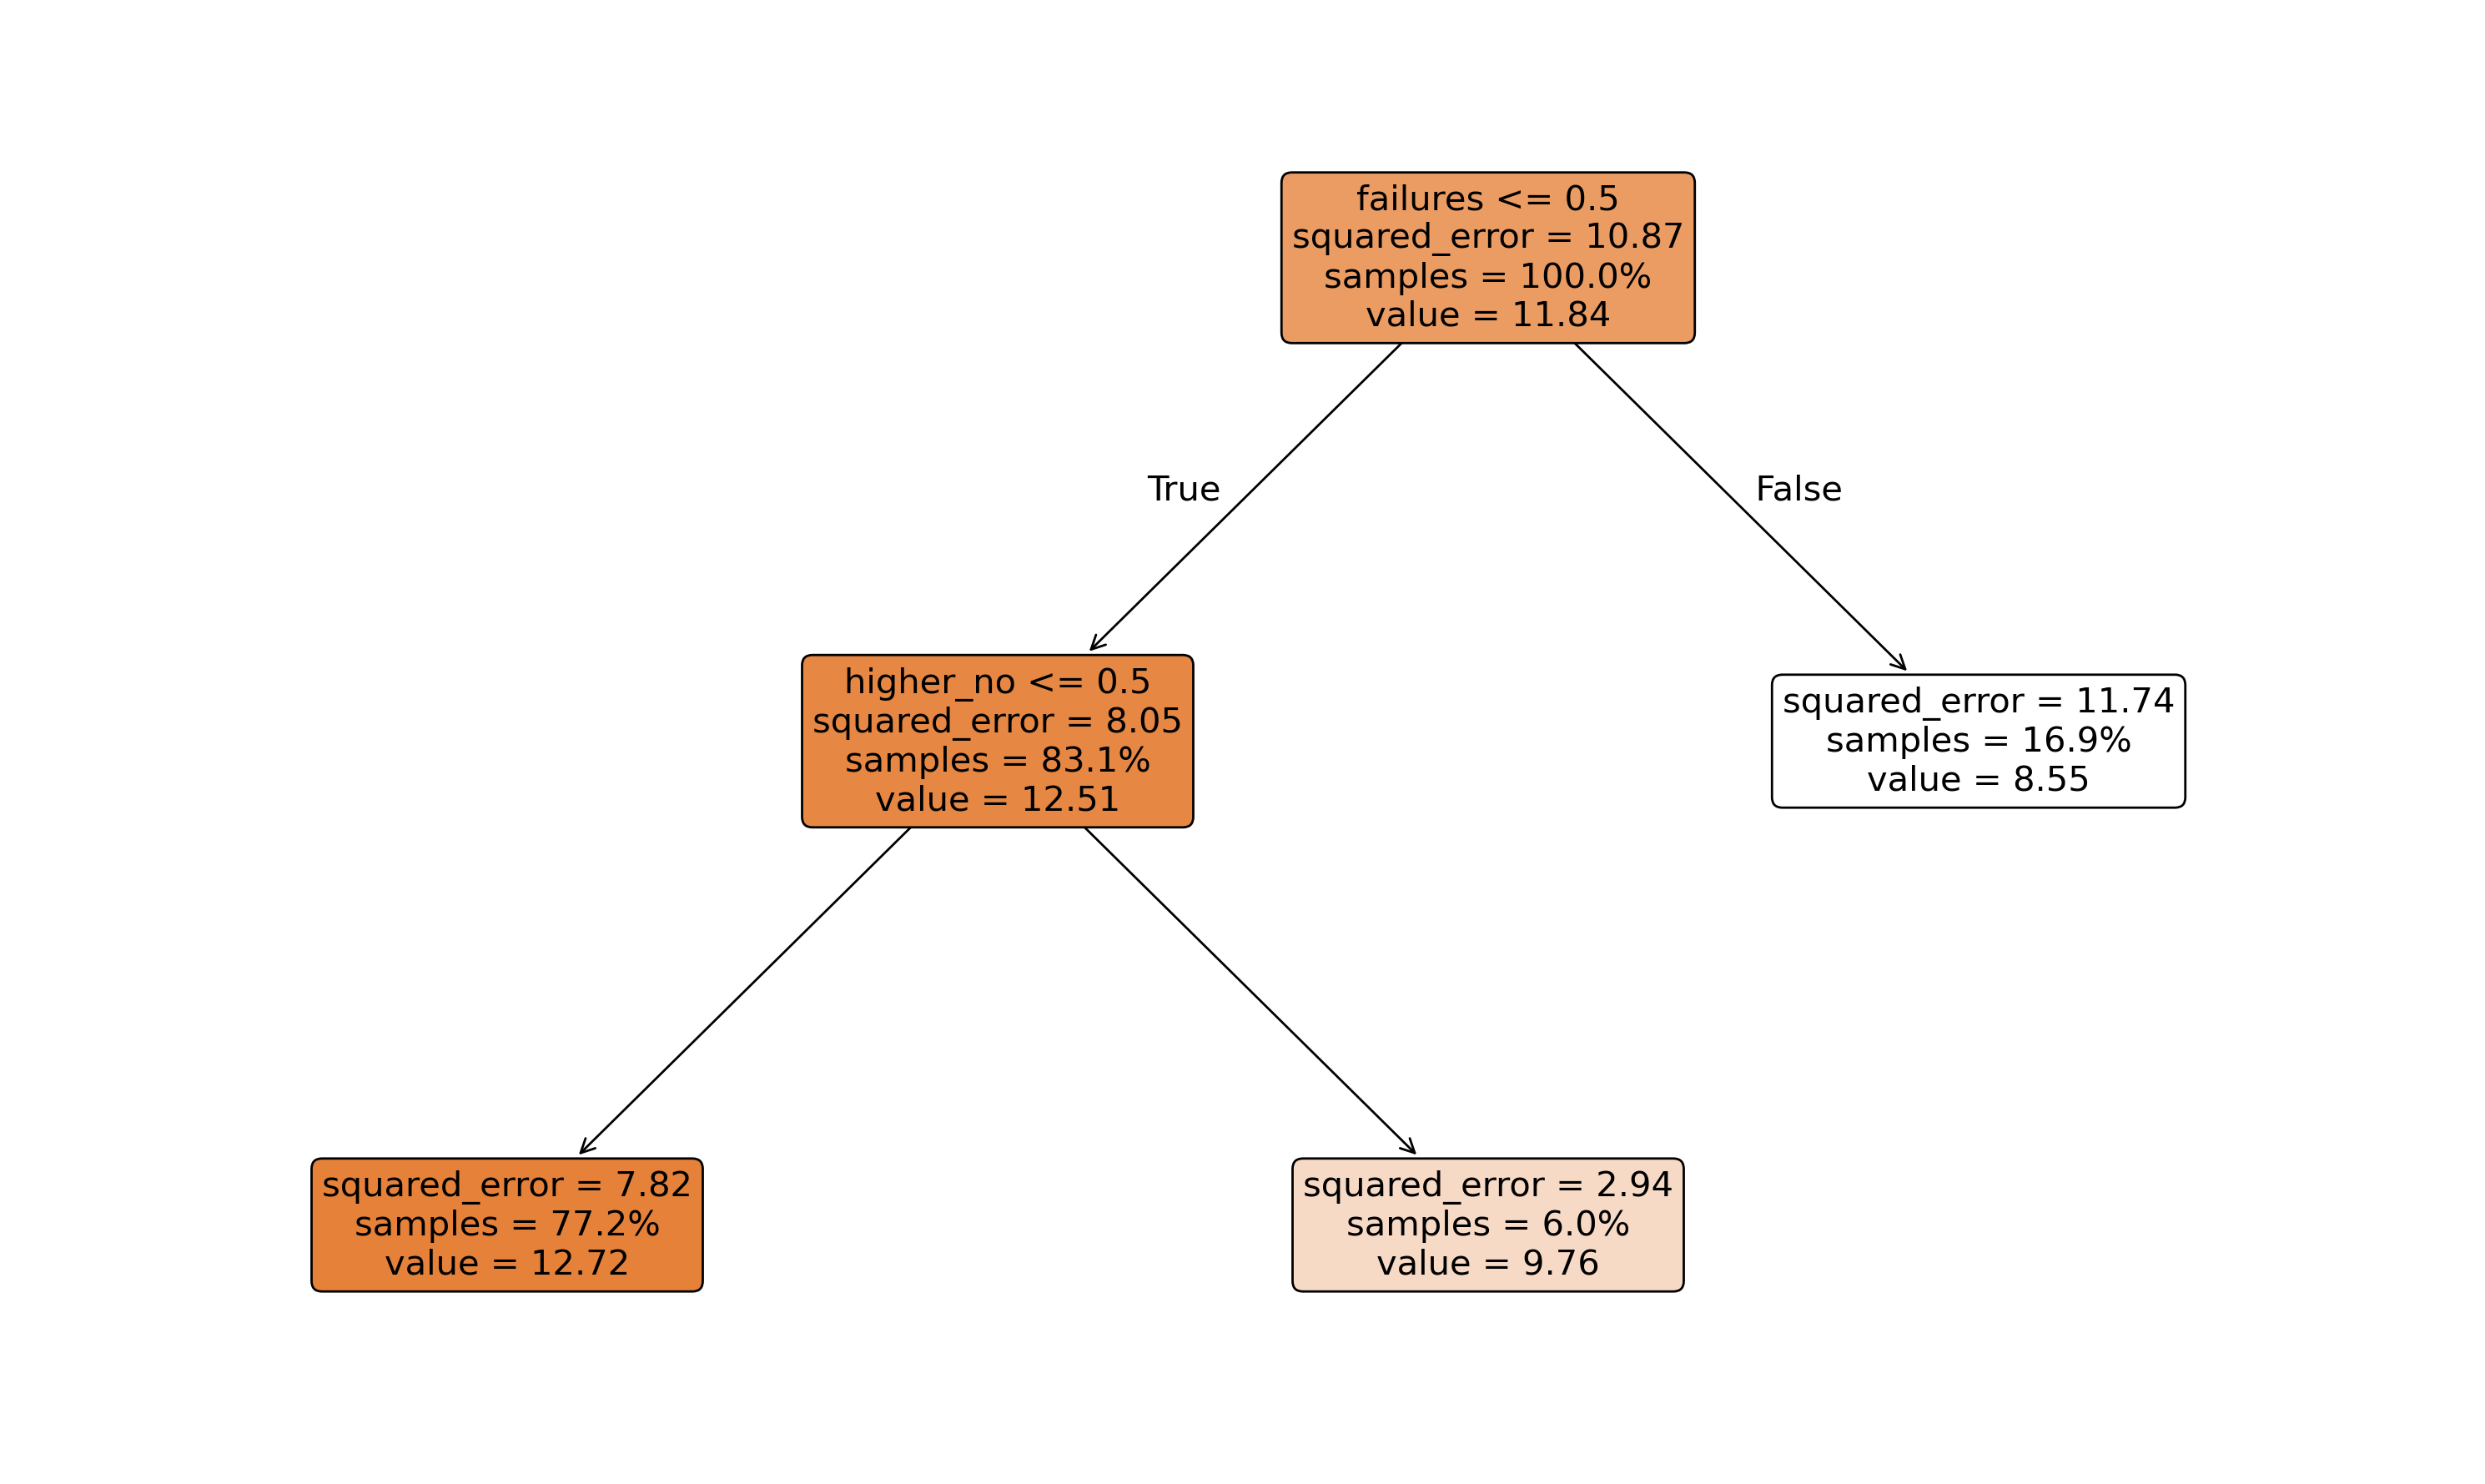

In [16]:

plt.figure(figsize=(15, 9), dpi=200)

plot_tree(
    dt_pruned,
    filled=True,
    rounded=True,
    feature_names=X_encoded.columns,
    max_depth=3,            
    fontsize=15,             
    precision=2,            
    proportion=True         
)

plt.tight_layout()
plt.show()


Now that we fit a Decision forest, how do we know if it's any good?

There is many evaluation tests to check the accuracy of a Model, DecisionTreeRegressor doesn't allow any confusion matrix.

In [17]:
train_preds = dt_pruned.predict(X_train)
test_preds = dt_pruned.predict(X_test)

train_rmse = np.sqrt(mean_squared_error(y_train, train_preds))
test_rmse = np.sqrt(mean_squared_error(y_test, test_preds))

print('Train RMSE:', train_rmse)
print('Test RMSE:', test_rmse)

Train RMSE: 2.8614132249254967
Test RMSE: 2.7364953970115797


In [20]:
from sklearn.metrics import r2_score
r2 = r2_score(y_test, test_preds)
print('R-squared:',r2)

R-squared: 0.17034532704878802


In [21]:
from sklearn.metrics import mean_absolute_error
mae = mean_absolute_error(y_test, test_preds)
print('MAE:' ,mae)

MAE: 1.9951473372994784


There is an obvious improvment in all the three evaluation tests, meaning the decision tree became more accurate after the pruning.